In [1]:
# CPU/GPU selection: run this cell before importing jax or bfm elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
# GPU mode requires CUDA-enabled JAX in a Linux/WSL2 kernel.
import os

MODE = "cpu"  # "cpu" or "gpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')

# Keep CPU available in GPU mode for operations explicitly placed on CPU.
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax
backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())


Backend: cpu
Devices: [CpuDevice(id=0)]


# Demo 2: `bfm` unified interface — sparse random loadings, heteroscedastic noise (test2 design)

**Model**: $x_i = B\eta_i + \varepsilon_i$, $\eta_i \sim \mathcal N_K(0, I)$,
$\varepsilon_i \sim \mathcal N_p(0, \Omega)$, $\Omega$ diagonal.

**Data design** (replicates `test/test2.py` of BFM_GS, $n = 100 \ll p = 1000$, $r = 5$ true factors):

- entries of $B_0$ are $\mathrm{Bernoulli}(1/3) \times U(0,1)$ — sparse random loadings with about 2/3 exact zeros;
- $\Omega_0 = \mathrm{diag}(\sigma_j^2)$ with $\sigma_j^2 \sim U(0.1, 1.0)$ — **heteroscedastic** noise (unlike Demo 1);
- $\Sigma_0 = B_0 B_0^\top + \Omega_0$.

**Inference** through the unified `bfm` interface, on the SAME data: `GibbsBFM` (exact MCMC) and `CaviBFM` (fast deterministic approximation).

In [2]:
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# the notebook lives in BFM/examples/: walk up to the directory containing
# the bfm package and put it on sys.path
root = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "bfm").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import jax
from bfm import CaviBFM, GibbsBFM

# ---------------------------------------------------------------------------
# Consistent, publication-friendly plotting style shared by both demos.
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6eaf0",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 8,
    "axes.labelsize": 10,
    "axes.labelcolor": "#30363f",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.color": "#30363f",
    "ytick.color": "#30363f",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
C_GIBBS, C_CAVI, C_TRUE, C_SHRUNK = "#2f6fd0", "#e07b39", "#b03a2e", "#c9d3df"

print("package root:", root, "| jax backend:", jax.default_backend())


package root: C:\Users\kexio\iCloudDrive\Code\LH_BFM | jax backend: cpu


## 1. Simulate the data (same design, new random seed)

In [3]:
from scipy.stats import uniform

DATA_SEED = 12
SAMPLER_SEED = 2026
np.random.seed(DATA_SEED)
print(f"Seeds: data={DATA_SEED}, Gibbs/scores={SAMPLER_SEED}")

P, K0, N = 1000, 5, 100
B_0 = np.random.binomial(1, 1 / 3, (P, K0)) * np.random.rand(P, K0)
s2_true = uniform.rvs(loc=0.1, scale=0.9, size=P)          # in [0.1, 1.0]
cov_0 = B_0 @ B_0.T + np.diag(s2_true)
X = np.random.multivariate_normal(np.zeros(P), cov_0, N)

Sig_true = cov_0
print(f"X: {X.shape}  (n = {N}, p = {P}, true factors r = {K0})")
print(f"loading sparsity (exact zeros): {(B_0 == 0).mean():.2%}")


Seeds: data=12, Gibbs/scores=2026


X: (100, 1000)  (n = 100, p = 1000, true factors r = 5)
loading sparsity (exact zeros): 67.50%


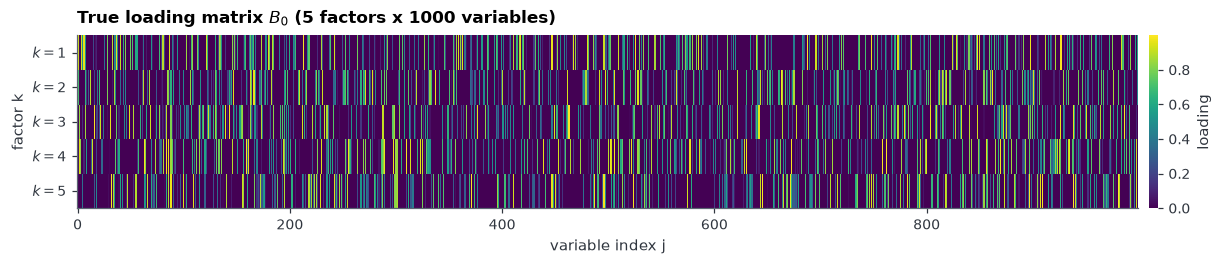

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.3), constrained_layout=True)
im = ax.imshow(B_0.T, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_title(f"True loading matrix $B_0$ ({K0} factors x {P} variables)", loc="left")
ax.set_xlabel("variable index j")
ax.set_ylabel("factor k")
ax.set_yticks(np.arange(K0))
ax.set_yticklabels([f"$k={k + 1}$" for k in range(K0)])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("loading")
cb.outline.set_visible(False)
plt.show()


## 2. Fit both estimators on the same data

Same settings as Demo 1: truncation K = 50 > r = 5, Gibbs retains its default prior `a=10.0, c1=2.0, c2=1.0`, while CAVI uses `a=10.0, c1=2.3, c2=1.0`, with `a_sigma = b_sigma = 1` left at their defaults (theory-satisfying), shared centering, seeded Gibbs / deterministic CAVI.

CAVI checks the absolute change in the variable ELBO after each complete sweep: `abs(Lvar_t - Lvar_prev) < tol`, with `tol=1e-1`. The independent `drop_budget` (default 0.5) rejects larger ELBO decreases with `FloatingPointError` instead of reporting convergence. The outputs below are regenerated with these settings.
The CAVI loading-mean count uses `LINF_THRESHOLD = 0.1` throughout, including the aligned summaries. Gibbs retains its credible-interval selection rule.


In [5]:
K = 50  # truncation level, over-fitted on purpose (true r = 5)
LINF_THRESHOLD = 0.1  # CAVI loading-mean selection cutoff

# --- exact MCMC: Gibbs sampler (Section 3) ---
t0 = time.perf_counter()
gs = GibbsBFM(K=K, a=10.0, c1=2.0, c2=1.0, n_iter=2000, burn_in=1000, seed=SAMPLER_SEED, verbose=False).fit(X)
wall_gs = time.perf_counter() - t0
S = gs.B_samples_.shape[0]

# --- fast approximation: CAVI (Section 4 / Algorithm 1), deterministic ---
t0 = time.perf_counter()
vi = CaviBFM(K=K, a=10.0, c1=2.3, c2=1.0, max_iter=1000, tol=1e-1).fit(X)
wall_vi = time.perf_counter() - t0

print("-" * 86)
print(f"GibbsBFM | {S} kept draws | scan {gs.runtime_sec_:.1f}s "
      f"({1e3 * gs.runtime_sec_ / 2000:.1f} ms/sweep) | wall {wall_gs:.1f}s")
print(f"CaviBFM  | converged={vi.converged_} ({vi.stop_reason_}) in "
      f"{vi.n_iter_} sweeps | ELBO={vi.elbo_[-1]:.1f} | loop {vi.runtime_sec_:.1f}s")
print("-" * 86)


--------------------------------------------------------------------------------------
GibbsBFM | 1000 kept draws | scan 32.5s (16.3 ms/sweep) | wall 38.0s
CaviBFM  | converged=True (tol) in 642 sweeps | ELBO=-143150.9 | loop 23.3s
--------------------------------------------------------------------------------------


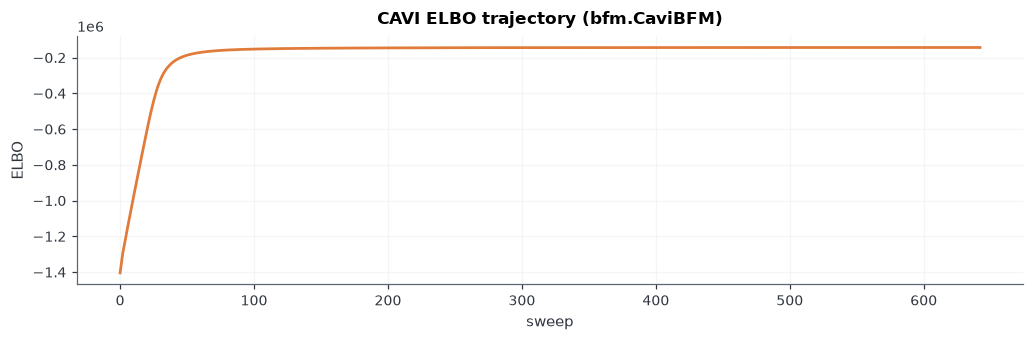

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
vi.plot_elbo(ax=ax, show=False, title="CAVI ELBO trajectory (bfm.CaviBFM)")
ax.lines[0].set_color(C_CAVI)
ax.lines[0].set_linewidth(1.8)
ax.grid(True, alpha=0.45)
plt.show()


## 3. Automatic selection of the factor dimension

Compare Gibbs' empirical marginal credible-interval count with two CAVI summaries: `method="credible"` uses the Gaussian interval $|\mu_{jk}| > z\sqrt{V_{jkk}}$, while `method="linf"` counts columns satisfying $\max_j |\mu_{jk}| > 0.1$ (`threshold=0.1`). Equality at the threshold is inactive. The credible-interval rule accounts for marginal posterior uncertainty; the threshold rule uses loading means only, so their counts can differ. Compare the computed counts with the true factor dimension $r=5$.

The bars below show column $L_2$ norms for scale and shrinkage visualization. These plotted norms are distinct from both the credible-interval criterion and the CAVI $L_\infty$ threshold criterion.


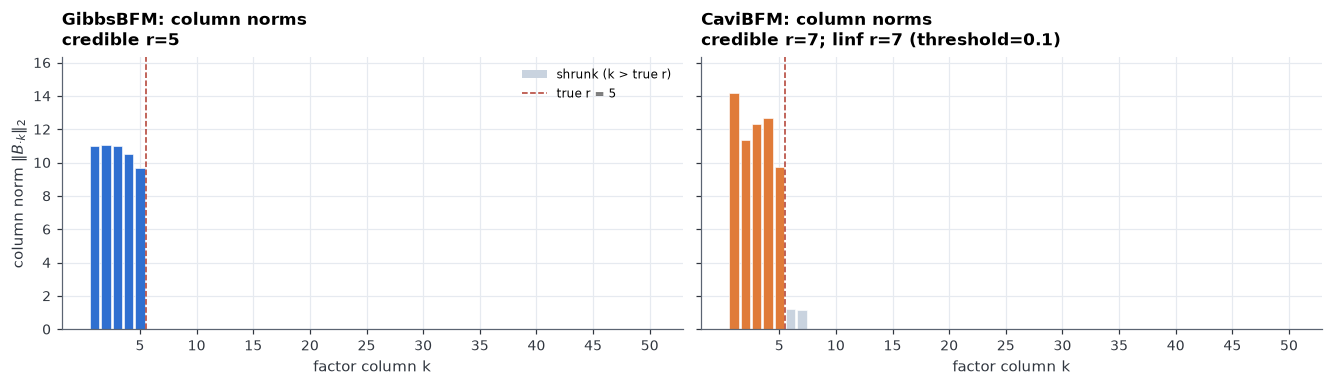

column norms (Gibbs): [1.0978e+01 1.1029e+01 1.0996e+01 1.0496e+01 9.6520e+00 5.0000e-03
 2.0000e-03 1.0000e-03 1.0000e-03 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 0.0000e+00]
column norms (CAVI):  [14.181 11.331 12.343 12.655  9.712  1.238  1.134  0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
  0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
true factor count: 5
Gibbs n_factors (credible): 5
C

In [7]:
r_gs_credible = gs.n_factors()
r_vi_credible = vi.n_factors(method="credible")
r_vi_linf = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)

colnorm_gs = np.linalg.norm(gs.B_samples_, axis=1).mean(0)  # posterior mean ||B_{.k}||
colnorm_vi = np.linalg.norm(vi.mu_, axis=0)                 # ||mu_{.k}||

# Linear axis: show the actual column norms.  The strongly shrunk tail is
# essentially zero on this scale, which is the point of the increasing
# shrinkage prior; no logarithmic transform or artificial floor is used.
all_norms = (colnorm_gs, colnorm_vi)
ymax = max(float(n.max()) for n in all_norms) * 1.15


def _draw_colnorms(ax, norms, count_label, color, title):
    xs = np.arange(1, len(norms) + 1)
    ax.bar(xs, norms, width=0.82,
           color=np.where(xs <= K0, color, C_SHRUNK),
           edgecolor="white", linewidth=0.4)
    ax.axvline(K0 + 0.5, color=C_TRUE, ls="--", lw=1.0)
    ax.set_title(f"{title}: column norms\n{count_label}",
                 loc="left")
    ax.set_xlabel("factor column k")
    ax.set_ylim(0, ymax)
    ax.set_xticks(np.arange(5, len(norms) + 1, 5))


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         sharey=True)
_draw_colnorms(axes[0], colnorm_gs, f"credible r={r_gs_credible}",
               C_GIBBS, "GibbsBFM")
_draw_colnorms(axes[1], colnorm_vi,
               f"credible r={r_vi_credible}; linf r={r_vi_linf} (threshold={LINF_THRESHOLD:g})",
               C_CAVI, "CaviBFM")
axes[0].set_ylabel(r"column norm $\|B_{\cdot k}\|_2$")

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

handles = [
    Patch(facecolor=C_SHRUNK, label="shrunk (k > true r)"),
    Line2D([0], [0], color=C_TRUE, ls="--", lw=1.0,
           label=f"true r = {K0}"),
]
axes[0].legend(handles=handles, loc="upper right", fontsize=8)
plt.show()

print("column norms (Gibbs):", np.round(colnorm_gs, 3))
print("column norms (CAVI): ", np.round(colnorm_vi, 3))
print(f"true factor count: {K0}")
print(f"Gibbs n_factors (credible): {r_gs_credible}")
print(f"CAVI n_factors (credible): {r_vi_credible}")
print(f"CAVI n_factors (linf, threshold={LINF_THRESHOLD:g}): {r_vi_linf}")


## 4. Recovery of the heteroscedastic noise variances

$\sigma^2$ estimates vs the truth: the Gibbs posterior mean and the variational posterior mean $E_q[\sigma_j^2] = \beta_j/(\alpha_n - 1)$.

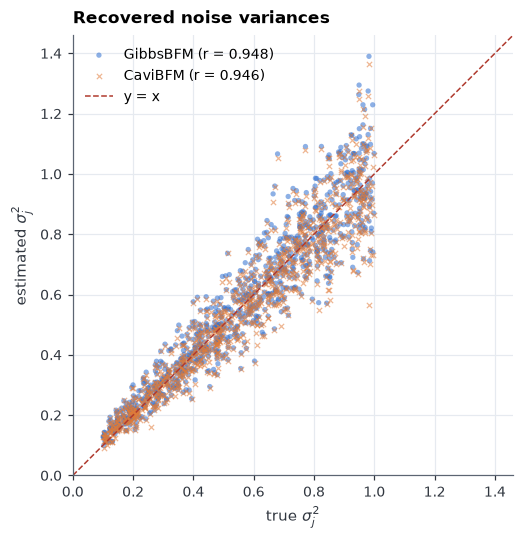

corr with truth: Gibbs = 0.9483, CAVI = 0.9455
mean |err|:      Gibbs = 0.0627, CAVI = 0.0625


In [8]:
corr_gs = np.corrcoef(s2_true, gs.sigma2_hat_)[0, 1]
corr_vi = np.corrcoef(s2_true, vi.sigma2_hat_)[0, 1]
err_gs = np.abs(gs.sigma2_hat_ - s2_true).mean()
err_vi = np.abs(vi.sigma2_hat_ - s2_true).mean()

fig, ax = plt.subplots(figsize=(5.6, 4.8), constrained_layout=True)
ax.scatter(s2_true, gs.sigma2_hat_, s=12, alpha=0.55, color=C_GIBBS,
           edgecolors="none", label=f"GibbsBFM (r = {corr_gs:.3f})")
ax.scatter(s2_true, vi.sigma2_hat_, s=12, alpha=0.55, color=C_CAVI,
           marker="x", linewidths=0.8, label=f"CaviBFM (r = {corr_vi:.3f})")
lim = [0, 1.05 * max(float(s2_true.max()), float(gs.sigma2_hat_.max()),
                     float(vi.sigma2_hat_.max()))]
ax.plot(lim, lim, color=C_TRUE, ls="--", lw=1.0, label="y = x")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect("equal")
ax.set_xlabel(r"true $\sigma_j^2$")
ax.set_ylabel(r"estimated $\sigma_j^2$")
ax.set_title("Recovered noise variances", loc="left")
ax.legend(loc="upper left")
plt.show()

print(f"corr with truth: Gibbs = {corr_gs:.4f}, CAVI = {corr_vi:.4f}")
print(f"mean |err|:      Gibbs = {err_gs:.4f}, CAVI = {err_vi:.4f}")


## 5. Recovered loading structure

$|B_0|$ (truth, 5 columns) vs the posterior-mean loadings $|B_{hat}|$ of GibbsBFM and the variational means $|\mu|$ of CaviBFM (K = 50 columns; the trailing ones are shrunk toward zero).

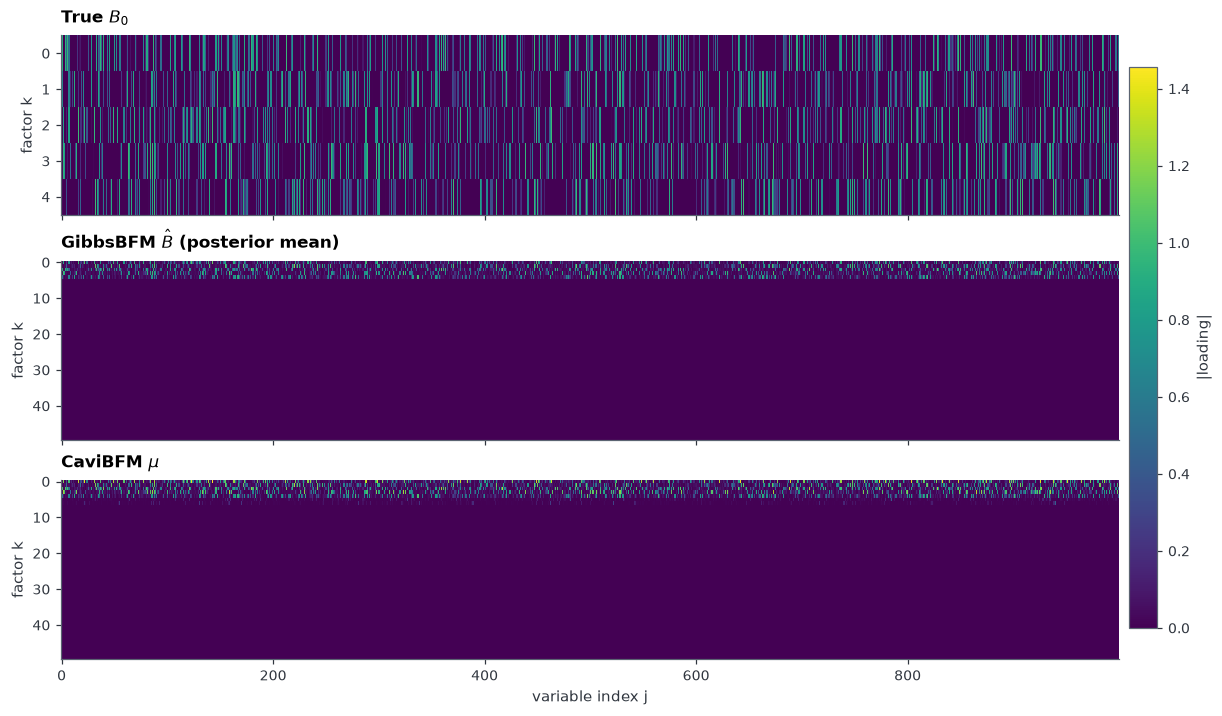

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), constrained_layout=True,
                         sharex=True)
matrices = (np.abs(B_0), np.abs(gs.B_hat_), np.abs(vi.mu_))
names = ("True $B_0$", "GibbsBFM $\\hat B$ (posterior mean)", "CaviBFM $\\mu$")
vmax = max(float(M.max()) for M in matrices)
for ax, M, name in zip(axes, matrices, names):
    im = ax.imshow(M.T, aspect="auto", interpolation="nearest", cmap="viridis",
                   vmin=0, vmax=vmax)
    ax.set_title(name, loc="left")
    ax.set_ylabel("factor k")
    ax.grid(False)
axes[-1].set_xlabel("variable index j")
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label("|loading|")
plt.show()


## 6. Covariance and factor-subspace recovery

For each estimator, report both the plug-in covariance and the posterior-mean covariance using
\[
\text{Frobenius error}=\|\widehat\Sigma-\Sigma_0\|_F,
\qquad
\text{relative Frobenius error}
=\frac{\|\widehat\Sigma-\Sigma_0\|_F}{\|\Sigma_0\|_F}.
\]
The table and plots below report both errors **before RSP alignment**. The absolute error retains the covariance scale; the relative error normalizes by the same true-covariance norm for all four estimates.


Covariance estimation errors before RSP alignment
||Sigma_true||_F = 271.420766
Estimator / summary             Frobenius error   Relative Frobenius error
GibbsBFM plug-in                      69.438129                   0.255832
GibbsBFM Sigma_mean_                  69.456228                   0.255899
CaviBFM plug-in                      135.653646                   0.499791
CaviBFM Sigma_mean_                  135.696068                   0.499947
principal-angle cosines (GibbsBFM): [0.9919 0.9821 0.9803 0.9787 0.976 ]
principal-angle cosines (CaviBFM): [0.9916 0.9812 0.9793 0.9778 0.9746]


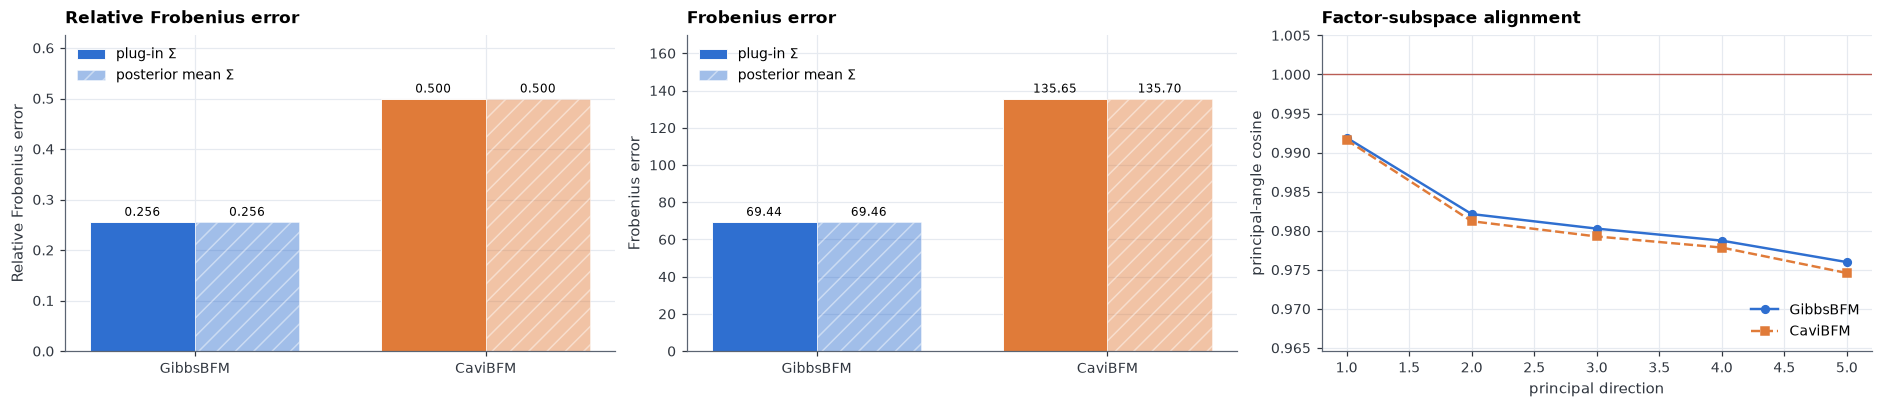

In [10]:
# Covariance recovery before RSP alignment.
# Compare the plug-in covariance and the posterior-mean covariance
# E[Sigma | X] (Gibbs) / E_q[Sigma] (CAVI) against the same truth.
Sig_gs_mean = gs.Sigma_mean_
Sig_vi_mean = vi.Sigma_mean_
norm_Sig_true = float(np.linalg.norm(Sig_true, ord="fro"))


def froerr(Sig):
    return float(np.linalg.norm(Sig - Sig_true, ord="fro"))


def relerr(Sig):
    return froerr(Sig) / norm_Sig_true


fro_gs_plug, fro_gs_mean = froerr(gs.Sigma_), froerr(Sig_gs_mean)
fro_vi_plug, fro_vi_mean = froerr(vi.Sigma_), froerr(Sig_vi_mean)
rel_gs_plug, rel_gs_mean = fro_gs_plug / norm_Sig_true, fro_gs_mean / norm_Sig_true
rel_vi_plug, rel_vi_mean = fro_vi_plug / norm_Sig_true, fro_vi_mean / norm_Sig_true
covariance_errors = {
    "GibbsBFM plug-in": (fro_gs_plug, rel_gs_plug),
    "GibbsBFM Sigma_mean_": (fro_gs_mean, rel_gs_mean),
    "CaviBFM plug-in": (fro_vi_plug, rel_vi_plug),
    "CaviBFM Sigma_mean_": (fro_vi_mean, rel_vi_mean),
}
print("Covariance estimation errors before RSP alignment")
print(f"||Sigma_true||_F = {norm_Sig_true:.6f}")
print(f"{'Estimator / summary':<26} {'Frobenius error':>20} {'Relative Frobenius error':>26}")
for label, (absolute, relative) in covariance_errors.items():
    print(f"{label:<26} {absolute:20.6f} {relative:26.6f}")

# subspace alignment: principal-angle cosines between the span of the top-r
# estimated loading columns and the true factor space (1 = aligned)
U_true = np.linalg.qr(B_0)[0][:, :K0]
cos_gs, cos_vi = [], []
for name, Bh, store in (("GibbsBFM", gs.B_hat_, cos_gs),
                        ("CaviBFM", vi.B_hat_, cos_vi)):
    U_post = np.linalg.qr(Bh)[0][:, :K0]
    cosines = np.linalg.svd(U_post.T @ U_true, compute_uv=False)
    store.extend(cosines.tolist())
    print(f"principal-angle cosines ({name}):", np.round(cosines, 4))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), constrained_layout=True)
x = np.arange(2)
width = 0.36
panels = (
    (axes[0], [rel_gs_plug, rel_vi_plug], [rel_gs_mean, rel_vi_mean],
     "Relative Frobenius error", "%.3f"),
    (axes[1], [fro_gs_plug, fro_vi_plug], [fro_gs_mean, fro_vi_mean],
     "Frobenius error", "%.2f"),
)
for ax, plug_in, posterior_mean, label, number_format in panels:
    b1 = ax.bar(x - width / 2, plug_in, width,
                color=[C_GIBBS, C_CAVI], edgecolor="white", linewidth=0.6,
                label=r"plug-in $\Sigma$")
    b2 = ax.bar(x + width / 2, posterior_mean, width,
                color=[C_GIBBS, C_CAVI], alpha=0.45, hatch="//",
                edgecolor="white", linewidth=0.6,
                label=r"posterior mean $\Sigma$")
    ax.set_xticks(x)
    ax.set_xticklabels(["GibbsBFM", "CaviBFM"])
    ax.set_ylabel(label)
    ax.set_title(label, loc="left")
    ax.set_ylim(0, 1.25 * max(*plug_in, *posterior_mean))
    ax.legend(loc="upper left")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt=number_format, padding=2, fontsize=8)

axes[2].plot(np.arange(1, K0 + 1), cos_gs, "o-", ms=5, lw=1.6,
             color=C_GIBBS, label="GibbsBFM")
axes[2].plot(np.arange(1, K0 + 1), cos_vi, "s--", ms=5, lw=1.6,
             color=C_CAVI, label="CaviBFM")
axes[2].axhline(1.0, color=C_TRUE, lw=0.9, alpha=0.8)
axes[2].set_ylim(min(min(cos_gs), min(cos_vi)) - 0.01, 1.005)
axes[2].set_xlabel("principal direction")
axes[2].set_ylabel("principal-angle cosine")
axes[2].set_title("Factor-subspace alignment", loc="left")
axes[2].legend(loc="lower right")
plt.show()


## 6c. Covariance heatmaps: truth vs posterior means

Heatmaps of (a) the true covariance $\Sigma_0$, (b) the Gibbs posterior-mean
covariance $E[\Sigma\mid X]$ (`gs.Sigma_mean_`) and (c) the CAVI
posterior-mean covariance $E_q[\Sigma]$ (`vi.Sigma_mean_`).  All panels share
one color scale.


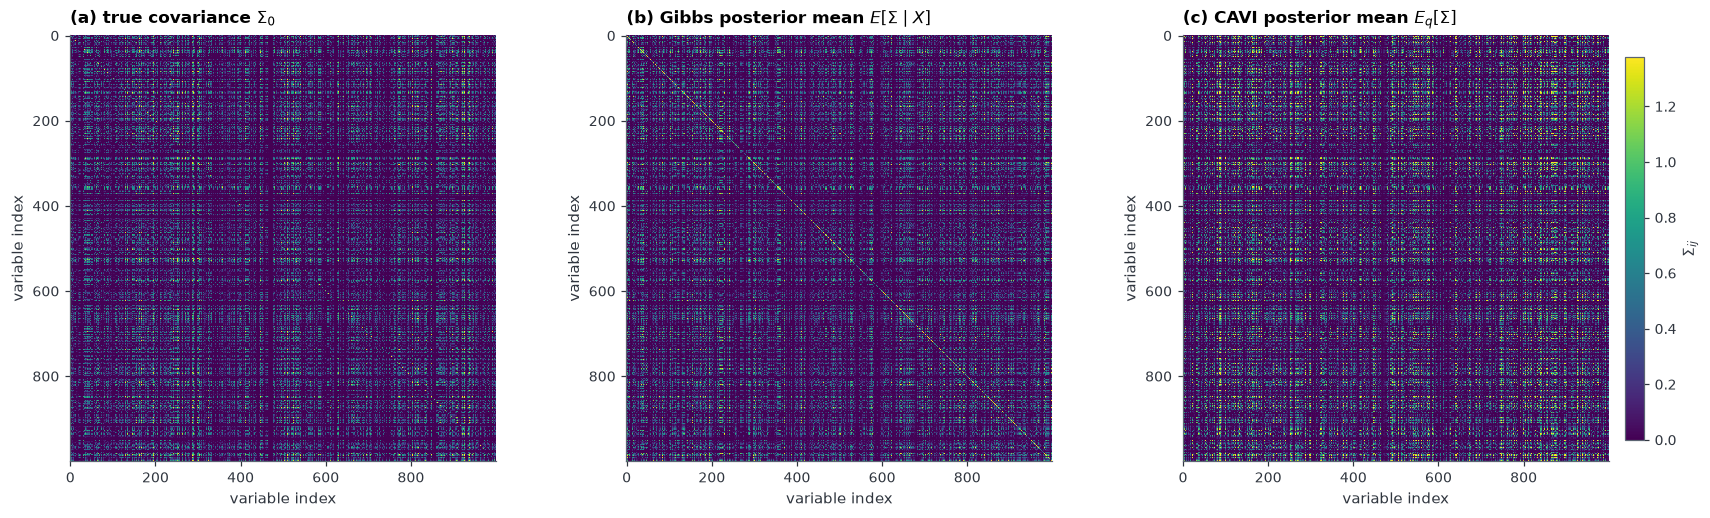

In [11]:
# (a) true covariance, (b) Gibbs posterior mean, (c) CAVI posterior mean
Sig_gs_mean = gs.Sigma_mean_
Sig_vi_mean = vi.Sigma_mean_
panels = (
    (r"(a) true covariance $\Sigma_0$", Sig_true),
    (r"(b) Gibbs posterior mean $E[\Sigma\mid X]$", Sig_gs_mean),
    (r"(c) CAVI posterior mean $E_q[\Sigma]$", Sig_vi_mean),
)
vmax = float(np.percentile(
    np.concatenate([np.asarray(M, dtype=float).ravel() for _, M in panels]),
    99.5,
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, cmap="viridis", vmin=0.0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_xlabel("variable index")
    ax.set_ylabel("variable index")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label(r"$\Sigma_{ij}$")
plt.show()


## 6b. Posterior uncertainty of $\Sigma$ (new covariance API)

Both estimators expose posterior moments of $\Sigma = BB^\top + \Omega$:
`Sigma_mean_` (posterior mean), `Sigma_var_`/`Sigma_sd_` (entrywise posterior
variance and standard deviation) and `cov_Sigma(pairs)` (selected entry-pair
covariances).  For `GibbsBFM` these are Monte Carlo estimates from the retained
draws; for `CaviBFM` they are closed-form moments of the mean-field variational
posterior.  Diagonal variances (`Sigma_diag_var_`) and selected pair
covariances always use all draws and are cheap; the full $p \times p$ variance
matrix is additionally guarded by a compute budget for large $p$.


posterior SD of Sigma_jj: Gibbs mean = 0.142, CAVI mean = 0.150
Gibbs: Var(Sigma_01) = 1.362e-02, Cov(Sigma_01, Sigma_23) = -2.224e-03 (all 1000 draws)


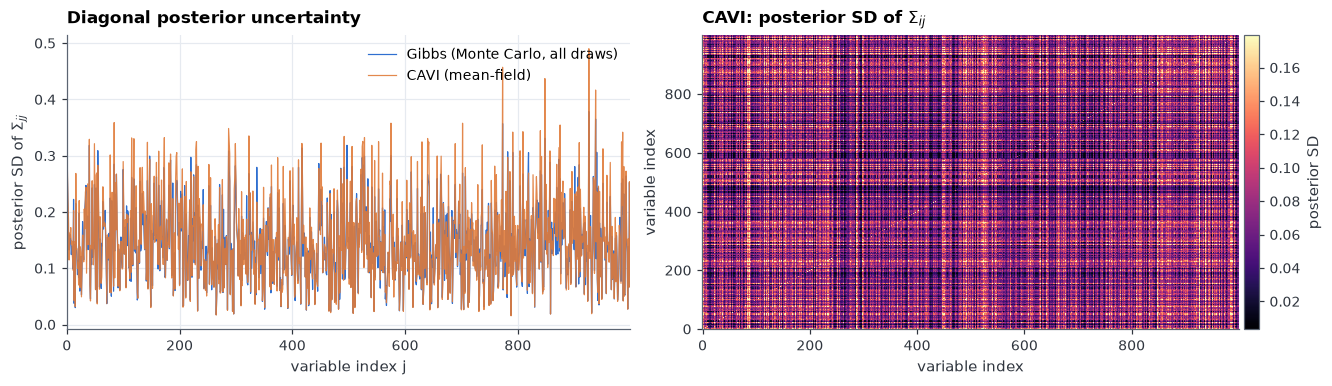

In [12]:
# ---- posterior uncertainty of Sigma (new covariance API) -------------------
gs_sd_diag = np.sqrt(gs.Sigma_diag_var_)       # (p,), all draws, cheap
vi_sd_diag = np.sqrt(np.diag(vi.Sigma_var_))   # closed form; ~0.4 s at p=1956
pair_var = float(gs.cov_Sigma([((0, 1), (0, 1))])[0])
pair_cov = float(gs.cov_Sigma([((0, 1), (2, 3))])[0])
print(f"posterior SD of Sigma_jj: Gibbs mean = {gs_sd_diag.mean():.3f}, "
      f"CAVI mean = {vi_sd_diag.mean():.3f}")
print(f"Gibbs: Var(Sigma_01) = {pair_var:.3e}, "
      f"Cov(Sigma_01, Sigma_23) = {pair_cov:.3e} "
      f"(all {gs.B_samples_.shape[0]} draws)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.05, 1.0]})
axes[0].plot(gs_sd_diag, color=C_GIBBS, lw=0.8,
             label="Gibbs (Monte Carlo, all draws)")
axes[0].plot(vi_sd_diag, color=C_CAVI, lw=0.8, alpha=0.9,
             label="CAVI (mean-field)")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel(r"posterior SD of $\Sigma_{jj}$")
axes[0].set_title("Diagonal posterior uncertainty", loc="left")
axes[0].set_xlim(0, P - 1)
axes[0].legend(loc="upper right")

im = axes[1].imshow(vi.Sigma_sd_, aspect="auto", origin="lower",
                    interpolation="nearest", cmap="magma",
                    vmax=float(np.percentile(vi.Sigma_sd_, 99)))
axes[1].set_xlabel("variable index")
axes[1].set_ylabel("variable index")
axes[1].set_title(r"CAVI: posterior SD of $\Sigma_{ij}$", loc="left")
axes[1].grid(False)
cb = fig.colorbar(im, ax=axes[1], pad=0.01)
cb.set_label("posterior SD")
plt.show()


## 7. MCMC mixing diagnostics (ESS, ArviZ)

B       min=     1.8  median=   952.6  mean=   923.1  max=  1489.3  (draws=1000)
sigma2  min=   441.1  median=   880.7  mean=   870.6  max=  1201.9  (draws=1000)


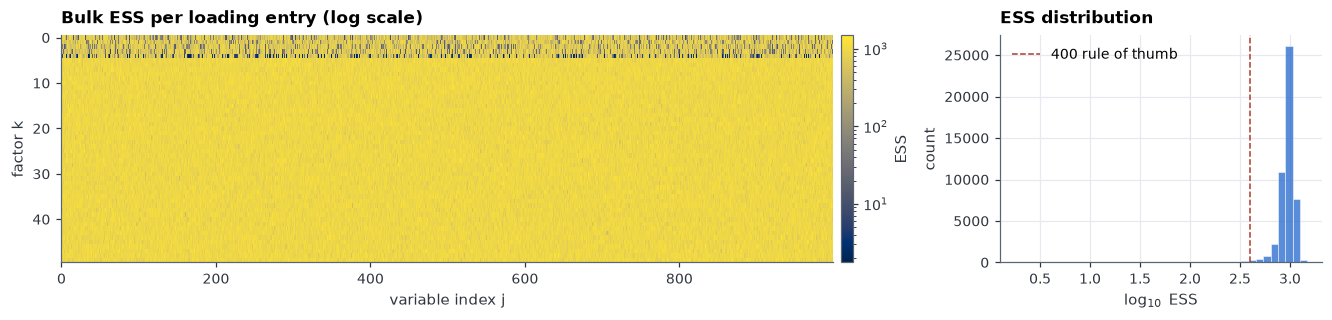

In [13]:
summary = gs.ess_summary()
for k, v in summary.items():
    print(f"{k:7s} min={v['min']:8.1f}  median={v['median']:8.1f}  "
          f"mean={v['mean']:8.1f}  max={v['max']:8.1f}  "
          f"(draws={v['n_draws']})")

from matplotlib.colors import LogNorm

ess_B = gs.ess()["B"]
vals = ess_B.ravel()
vals = vals[np.isfinite(vals) & (vals > 0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2.4, 1.0]})
im = axes[0].imshow(ess_B.T, aspect="auto", interpolation="nearest",
                    norm=LogNorm(vmin=max(1.0, float(np.min(vals))),
                                 vmax=float(np.max(vals))), cmap="cividis")
axes[0].set_title("Bulk ESS per loading entry (log scale)", loc="left")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel("factor k")
axes[0].grid(False)
cb = fig.colorbar(im, ax=axes[0], pad=0.01)
cb.set_label("ESS")
axes[1].hist(np.log10(vals), bins=40, color=C_GIBBS, alpha=0.8,
             edgecolor="white", linewidth=0.4)
axes[1].axvline(np.log10(400.0), color=C_TRUE, ls="--", lw=1.0,
                label="400 rule of thumb")
axes[1].set_title("ESS distribution", loc="left")
axes[1].set_xlabel(r"$\log_{10}$ ESS")
axes[1].set_ylabel("count")
axes[1].legend(loc="upper left")
plt.show()


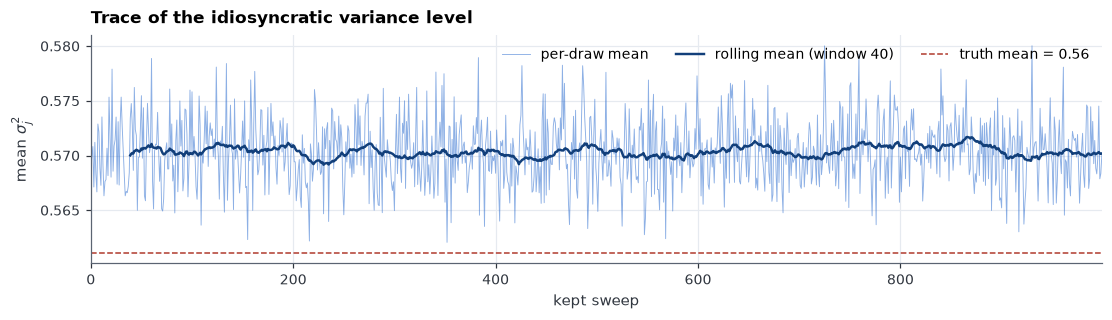

In [14]:
trace = gs.sigma2_samples_.mean(axis=1)
window = max(1, len(trace) // 25)
rolling = np.convolve(trace, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(trace, color=C_GIBBS, lw=0.6, alpha=0.55, label="per-draw mean")
ax.plot(np.arange(window - 1, len(trace)), rolling, color="#123f7a",
        lw=1.6, label=f"rolling mean (window {window})")
ax.axhline(float(s2_true.mean()), color=C_TRUE, ls="--", lw=1.0,
           label=f"truth mean = {float(s2_true.mean()):.2f}")
ax.set_xlabel("kept sweep")
ax.set_ylabel(r"mean $\sigma_j^2$")
ax.set_title("Trace of the idiosyncratic variance level", loc="left")
ax.set_xlim(0, len(trace) - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()


## 8. Factor switching: RSP alignment and factor scores

Apply alignment explicitly after the original fitting, recovery, and ESS diagnostics above. For the default **K = 50**, RSP's default assignment backend requires Optax; from the `BFM` directory install `python -m pip install -e ".[rsp]"` if needed.

- **Gibbs:** `gs.align_factors()` aligns every retained draw and updates `gs.B_hat_` to their aligned mean. `B_samples_` and ESS remain based on the original draws. Each draw's covariance is unchanged, but the plug-in `gs.Sigma_` can change because it uses the outer product of the new mean. `gs.n_factors()` (marginal credible intervals) works the same after alignment; `use_aligned=True` builds the intervals from the aligned draws (invariant to sign flips and column permutations, but not to the varimax rotation).
- **VI:** `vi.align_factors()` treats `mu_[None, :, :]` as one matrix to orient, not as an MCMC sample. It exposes `mu_aligned_`, score means `eta_aligned_ = W_aligned_.T`, and full transformed covariances `V_aligned_` and `Phi_aligned_`. The original parameters, `B_hat_`, `Sigma_`, both original-coordinate factor counts, and ELBO are unchanged. Both `method="credible"` and `method="linf"` support `use_aligned=True`; general rotations can change either count. The aligned threshold count uses `mu_aligned_` with `threshold=0.1`.
- **Scores on demand:** `gs.sample_factors(X, ...)` draws scores conditional on each retained loading/noise pair. Either output can be omitted with its return flag; both flags false return an empty dictionary. Pass the original uncentered `X`; the fitted centering offset is applied internally. These are fresh conditional draws, not the historical intermediate scores from the Gibbs sweeps.

The signed heatmaps use one color scale for each estimator's before/after pair. Orientation alone does not establish better recovery: the column-dependent shrinkage prior is not invariant to general rotations or permutations. The VI outputs are transformed moments for interpretation, not a new CAVI optimum. The checks below use one representative Gibbs draw and a small covariance submatrix to keep memory and computation bounded.


In [15]:
# Recover the raw means explicitly, so this section can be rerun safely.
gs_mean_raw = gs.B_samples_.mean(axis=0)
vi_mean_raw = vi.mu_.copy()
vi_elbo_before = tuple(vi.elbo_)
vi_count_before = vi.n_factors(method="credible")
vi_linf_count_before = vi.n_factors(method="linf", threshold=LINF_THRESHOLD)
check_features = np.unique(np.linspace(
    0, gs_mean_raw.shape[0] - 1, min(32, gs_mean_raw.shape[0]), dtype=int,
))
noise_block = np.diag(gs.sigma2_hat_[check_features])
gs_plugin_raw_block = (gs_mean_raw[check_features]
                       @ gs_mean_raw[check_features].T + noise_block)

gs.align_factors()
vi.align_factors()

for name, model in (("Gibbs", gs), ("VI", vi)):
    result = model.rsp_result_
    print(f"{name} RSP: status={int(result.status_code)}, "
          f"stop={result.diagnostics['stop_reason']}, "
          f"iterations={int(result.n_iter)}, final loss={float(result.loss_final):.6g}")
    print("  diagnostics:", result.diagnostics)

np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0), rtol=2e-5, atol=2e-6)
np.testing.assert_array_equal(vi.B_hat_, vi_mean_raw)
assert tuple(vi.elbo_) == vi_elbo_before
assert vi.n_factors(method="credible") == vi_count_before
assert vi.n_factors(method="linf", threshold=LINF_THRESHOLD) == vi_linf_count_before
print("Gibbs aligned mean:", gs.B_hat_.shape,
      "| VI transformed mean:", vi.mu_aligned_.shape)
print("VI B_hat_, ELBO and both original-coordinate factor counts are unchanged.")

print(f"CAVI aligned n_factors (credible): "
      f"{vi.n_factors(method='credible', use_aligned=True)}")
print(f"CAVI aligned n_factors (linf, threshold={LINF_THRESHOLD:g}): "
      f"{vi.n_factors(method='linf', threshold=LINF_THRESHOLD, use_aligned=True)}")


Gibbs RSP: status=1, stop=converged_threshold, iterations=2, final loss=24652.9
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'auto', 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
VI RSP: status=1, stop=converged_threshold, iterations=2, final loss=0
  diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'auto', 'rotate_requested': True, 'varimax_applied': True, 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}
Gibbs aligned mean: (1000, 50) | VI transformed mean: (1000, 50)
VI B_hat_, ELBO and both original-coordinate factor counts are unchanged.
CAVI aligned n_factors (credible): 7
CAVI aligned n_factors (linf, threshold=0.1): 7


### 8a. Counts and all column-wise posterior-mean infinity norms

Gibbs uses `a=10.0`; CAVI uses `a=10.0, c1=2.3, c2=1.0`. The table below compares Gibbs' credible-interval count and CAVI's credible-interval and loading-mean threshold counts, before and after RSP alignment. The CAVI threshold is `0.1`; equality is inactive. No threshold-based factor-selection API is applied to Gibbs.

For each loading column $k$, the reported quantity is $\max_j |\overline B_{jk}|$, the $L_\infty$ norm of that column of the posterior-mean loading matrix. Gibbs uses `B_samples_.mean(axis=0)` and `B_aligned_.mean(axis=0)`; CAVI uses `mu_` and `mu_aligned_`. These quantities differ from a mean of per-draw norms and from the $L_2$ bars in Section 3. All 50 columns are printed with nine significant digits so small nonzero values remain visible.


In [16]:
expected_priors = {
    "Gibbs": (10.0, 2.0, 1.0, 1.0, 1.0),
    "CAVI": (10.0, 2.3, 1.0, 1.0, 1.0),
}
for name, model in (("Gibbs", gs), ("CAVI", vi)):
    assert (model.a, model.c1, model.c2, model.a_sigma, model.b_sigma) == expected_priors[name]
    print(f"{name} hyperparameters: a={model.a:g}, c1={model.c1:g}, c2={model.c2:g}, "
          f"a_sigma={model.a_sigma:g}, b_sigma={model.b_sigma:g}")

factor_counts = {
    "Gibbs credible": (gs.n_factors(), gs.n_factors(use_aligned=True)),
    "CAVI credible": (vi.n_factors(method="credible"),
                      vi.n_factors(method="credible", use_aligned=True)),
    "CAVI linf": (vi.n_factors(method="linf", threshold=LINF_THRESHOLD),
                  vi.n_factors(method="linf", threshold=LINF_THRESHOLD,
                               use_aligned=True)),
}
print(f"a: Gibbs={gs.a:g}, CAVI={vi.a:g}; true factors={K0}; "
      f"credible level=0.95; linf threshold={LINF_THRESHOLD:g}")
print(f"{'Factor-count method':<24} {'Before':>10} {'Aligned':>10}")
for method, (before, after) in factor_counts.items():
    print(f"{method:<24} {before:>10d} {after:>10d}")

column_linf = {
    "Gibbs before": np.max(np.abs(gs.B_samples_.mean(axis=0)), axis=0),
    "Gibbs aligned": np.max(np.abs(gs.B_aligned_.mean(axis=0)), axis=0),
    "CAVI before": np.max(np.abs(vi.mu_), axis=0),
    "CAVI aligned": np.max(np.abs(vi.mu_aligned_), axis=0),
}
for norms in column_linf.values():
    assert norms.shape == (K,)
assert int((column_linf["CAVI before"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_.dtype)).sum()) == factor_counts["CAVI linf"][0]
assert int((column_linf["CAVI aligned"] > np.asarray(
    LINF_THRESHOLD, dtype=vi.mu_aligned_.dtype)).sum()) == factor_counts["CAVI linf"][1]

print("\nColumn infinity norms of posterior mean loadings (all columns):")
print(f"{'Column':>6}" + "".join(f"{label:>18}" for label in column_linf))
for k in range(K):
    print(f"{k + 1:6d}" + "".join(f"{norms[k]:18.9g}" for norms in column_linf.values()))


Gibbs hyperparameters: a=10, c1=2, c2=1, a_sigma=1, b_sigma=1
CAVI hyperparameters: a=10, c1=2.3, c2=1, a_sigma=1, b_sigma=1


a: Gibbs=10, CAVI=10; true factors=5; credible level=0.95; linf threshold=0.1
Factor-count method          Before    Aligned
Gibbs credible                    5          5
CAVI credible                     7          7
CAVI linf                         7          7

Column infinity norms of posterior mean loadings (all columns):
Column      Gibbs before     Gibbs aligned       CAVI before      CAVI aligned
     1        1.11196005        1.12772691        1.45748711        1.50410521
     2         1.1992352        1.19696045        1.25350988        1.25162935
     3        1.13959682        1.13292468        1.29862583        1.28709483
     4        1.07158315         1.0854547        1.30840933         1.3395257
     5         1.1200273        1.10042644        1.14306605        1.10900605
     6    1.54447825e-05    3.29460563e-05       0.412297577        0.41415751
     7    7.96364475e-06    2.68965869e-05       0.428302646       0.421996921
     8    3.85583826e-06    1.7447489

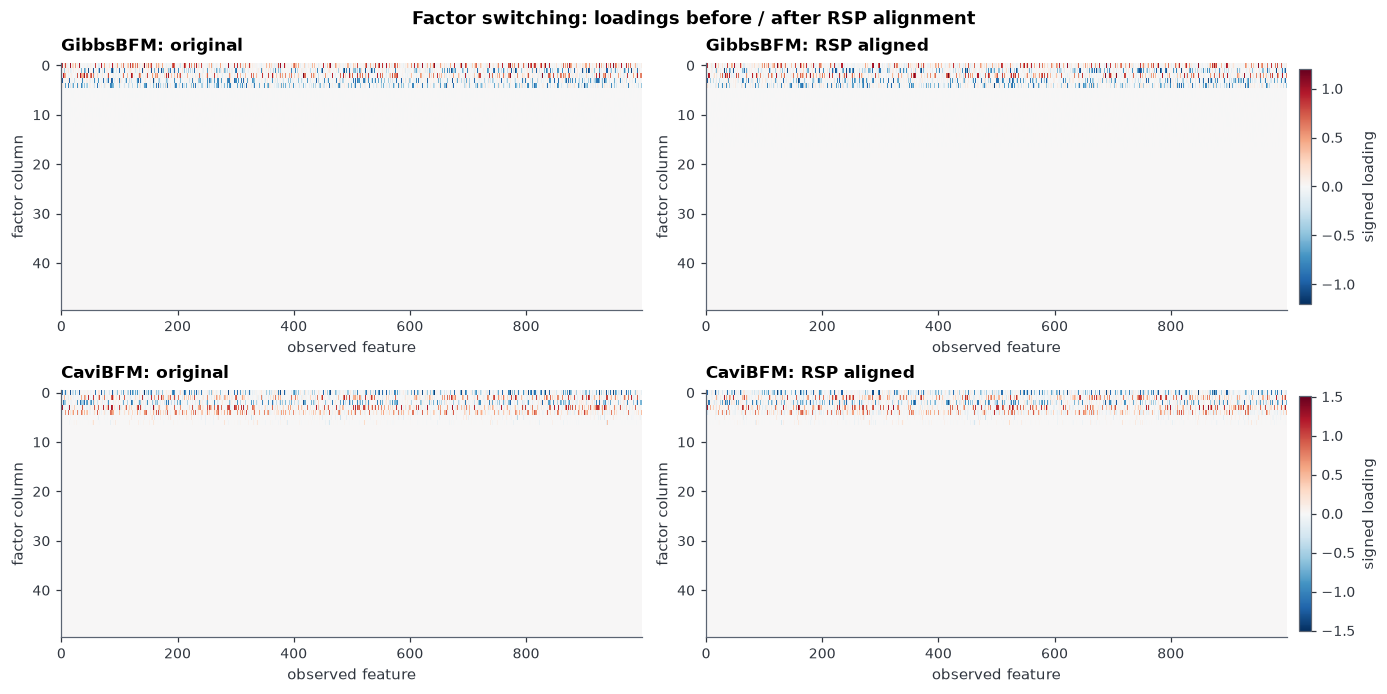

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.2), constrained_layout=True)
comparisons = (
    ("GibbsBFM", gs_mean_raw, gs.B_hat_),
    ("CaviBFM", vi_mean_raw, vi.mu_aligned_),
)
for row, (name, before, after) in enumerate(comparisons):
    limit = max(float(np.max(np.abs(before))), float(np.max(np.abs(after))), 1e-8)
    for col, (label, loadings) in enumerate((("original", before),
                                            ("RSP aligned", after))):
        ax = axes[row, col]
        im = ax.imshow(loadings.T, aspect="auto", interpolation="nearest",
                       cmap="RdBu_r", vmin=-limit, vmax=limit)
        ax.set_title(f"{name}: {label}", loc="left")
        ax.set_xlabel("observed feature")
        ax.set_ylabel("factor column")
        ax.grid(False)
    cb = fig.colorbar(im, ax=axes[row, :].tolist(), pad=0.01, shrink=0.95)
    cb.set_label("signed loading")
fig.suptitle("Factor switching: loadings before / after RSP alignment",
             fontweight="bold")
plt.show()


In [18]:
scores = gs.sample_factors(
    X, return_eta=True, return_eta_aligned=True, seed=SAMPLER_SEED, batch_size=32,
)
eta_sample = scores["eta_sample"]
eta_sample_aligned = scores["eta_sample_aligned"]
print("Gibbs eta_sample / eta_sample_aligned:",
      eta_sample.shape, eta_sample_aligned.shape, "(S, K, n)")
print("VI eta_aligned_ (posterior means):", vi.eta_aligned_.shape)
print("VI V_aligned_ / Phi_aligned_:", vi.V_aligned_.shape, vi.Phi_aligned_.shape)

def relative_difference(actual, expected):
    scale = max(float(np.linalg.norm(expected)), np.finfo(float).tiny)
    return float(np.linalg.norm(actual - expected)) / scale

# Compare paired scores for ONE draw and a small set of features.
s = gs.B_samples_.shape[0] // 2
B_raw_selected = gs.B_samples_[s, check_features]
B_aligned_selected = gs.B_aligned_[s, check_features]
common_raw = B_raw_selected @ eta_sample[s]
common_aligned = B_aligned_selected @ eta_sample_aligned[s]
np.testing.assert_allclose(common_aligned, common_raw, rtol=1e-4, atol=1e-4)
cov_raw = B_raw_selected @ B_raw_selected.T
cov_aligned = B_aligned_selected @ B_aligned_selected.T
np.testing.assert_allclose(cov_aligned, cov_raw, rtol=1e-4, atol=1e-4)
print(f"Gibbs draw {s}: relative B eta difference = "
      f"{relative_difference(common_aligned, common_raw):.3e}; "
      f"relative BB.T submatrix difference = {relative_difference(cov_aligned, cov_raw):.3e}")

# VI score means and loadings transform together; no draw axis is needed.
vi_common_raw = vi.mu_ @ vi.W_.T
vi_common_aligned = vi.mu_aligned_ @ vi.eta_aligned_
np.testing.assert_allclose(vi_common_aligned, vi_common_raw, rtol=1e-4, atol=1e-4)
print("VI relative common-component difference:",
      f"{relative_difference(vi_common_aligned, vi_common_raw):.3e}")

gs_plugin_aligned_block = (gs.B_hat_[check_features]
                           @ gs.B_hat_[check_features].T + noise_block)
print("Gibbs plug-in Sigma_ relative change on selected features:",
      f"{relative_difference(gs_plugin_aligned_block, gs_plugin_raw_block):.3e}")
# Sigma_ can change even though each aligned draw preserves BB.T.
# Avoid computing the full Sigma_mc_ here: it is expensive for large p.


Gibbs eta_sample / eta_sample_aligned: (1000, 50, 100) (1000, 50, 100) (S, K, n)
VI eta_aligned_ (posterior means): (50, 100)
VI V_aligned_ / Phi_aligned_: (1000, 50, 50) (50, 50)
Gibbs draw 500: relative B eta difference = 6.100e-07; relative BB.T submatrix difference = 6.386e-07
VI relative common-component difference: 4.399e-07
Gibbs plug-in Sigma_ relative change on selected features: 4.833e-03


## Summary

- Compare the current Gibbs credible-interval count and both CAVI counts (`credible` and `linf`, with `threshold=0.1`) against the true dimension $r=5$. Section 8 reports each count before and after alignment, followed by all 50 columns' posterior-mean $L_\infty$ norms.
- Use the noise-recovery, covariance-error, subspace, ELBO, and ESS outputs above to assess this run. Convergence status, iteration counts, and timings come from the current execution rather than historical benchmark values.
- Inspect the loading plots and the complete column-norm table to assess shrinkage and orientation. Alignment preserves fitted common components while general rotations can change the coordinate-wise factor counts.
